# Maschinelles Lernen (ML) - Übung 2
# Daten & Explorative Datenanalyse

In dieser Übung geht es um den ersten Schritt jedes ML-Projekts: die Arbeit mit den Rohdaten. Sie lernen `pandas` und `matplotlib` zur explorativen Datenanalyse (EDA) kennen, sowie Train/Test-Split, Skalierung und Kodierung als Standardschritte der Vorverarbeitung. Zum Abschluss betrachten wir ein subtiles, aber wichtiges Problem: *Data Leakage*.

Weitere Hintergründe finden Sie im PDF-Handout zu dieser Übung.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

np.random.seed(42)

**Aufgabe 1: Explorative Datenanalyse (EDA)**

Der Iris-Datensatz enthält je 50 Blüten dreier Schwertlilien-Arten mit vier gemessenen Merkmalen. Achten Sie auf die Bezeichnungen: *sepal* steht für das Kelchblatt, *petal* für das Blütenblatt. Die vier Merkmalsspalten sind also Kelchblattlänge und -breite (`sepal length (cm)`, `sepal width (cm)`) sowie Blütenblattlänge und -breite (`petal length (cm)`, `petal width (cm)`).

a) Laden Sie den Iris-Datensatz mit `load_iris(as_frame=True)`. Das Ergebnisobjekt besitzt ein Attribut `.frame` (bzw. `.data` und `.target`), das direkt einen `pandas`-`DataFrame` liefert, also eine Tabelle mit benannten Spalten (den Merkmalen) und je einer Zeile pro Blüte. Verschaffen Sie sich mit `.describe()` und `.info()` einen Überblick.

b) Stellen Sie die Verteilung der Spalte `petal length (cm)` (Blütenblattlänge) als Histogramm dar.

c) Erzeugen Sie ein Streudiagramm von `petal length (cm)` gegen `petal width (cm)`, wobei die Punkte nach Klasse (`target`, der Schwertlilien-Art) eingefärbt werden.

d) Berechnen Sie mit `.corr()` die paarweisen Korrelationen der numerischen Spalten. Welches Merkmalspaar korreliert am stärksten?

In [3]:
### Dein Code kommt hierhin:
iris = load_iris(as_frame=True)
df_iris = iris.frame
print("describe")
display(df_iris.describe())
print("info")
df_iris.info()
##########################
print("head")
df_iris.head()

describe


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


info
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
head


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


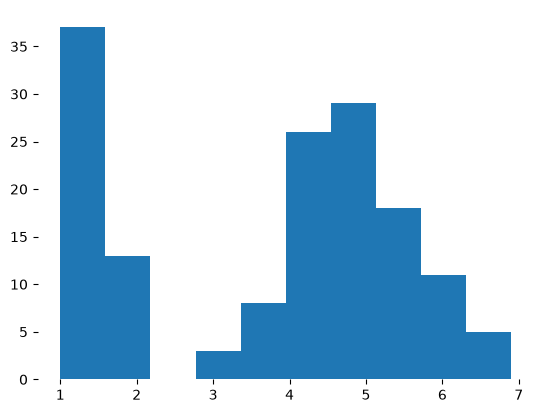

In [23]:
### Dein Code kommt hierhin:
col_petal_length=df_iris["petal length (cm)"]
plt.hist(col_petal_length)
plt.box(False)
plt.show()
##########################

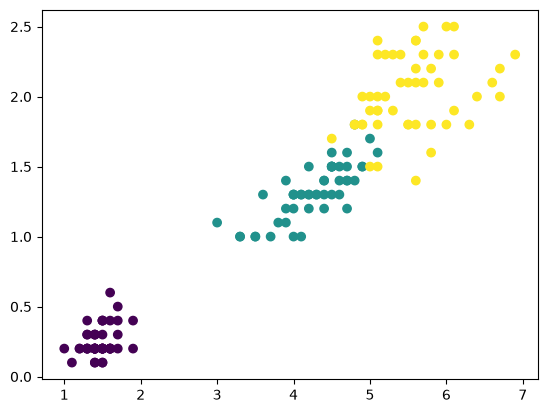

In [26]:
### Dein Code kommt hierhin:
col_petal_width=df_iris["petal width (cm)"]
colors=iris.target
plt.scatter(x=col_petal_length, y=col_petal_width, c=colors)
plt.show()
##########################

In [4]:
### Dein Code kommt hierhin:
korrelationen = df_iris.drop(columns="target").corr()
##########################
korrelationen

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


*Antwort:* Petal width und Petal length

## Ein kleiner, künstlicher Tabellendatensatz: "Fahrraddaten"

Für die folgenden Aufgaben erzeugen wir uns selbst einen kleinen Datensatz zu täglichen Fahrradverleihen: numerische Merkmale (`temperatur`, `luftfeuchtigkeit`), ein kategoriales Merkmal (`wochentyp`: `"Werktag"` oder `"Wochenende"`) sowie eine Zielgröße `ausleihen`. Damit die Vorverarbeitung später etwas zu tun hat, fügen wir absichtlich ein paar fehlende Werte (`NaN`) ein.

In [42]:
np.random.seed(42)
n = 50

temperatur = np.random.uniform(-5, 30, size=n)
luftfeuchtigkeit = np.random.uniform(30, 90, size=n)
wochentyp = np.random.choice(["Werktag", "Wochenende"], size=n, p=[5 / 7, 2 / 7])

bonus_wochenende = (wochentyp == "Wochenende") * 15
ausleihen = (
    50 + 4 * temperatur - 1.5 * luftfeuchtigkeit + bonus_wochenende
    + np.random.normal(0, 10, size=n)
)
ausleihen = np.clip(ausleihen, 0, None).round().astype(int)

df_bikes = pd.DataFrame({
    "temperatur": temperatur,
    "luftfeuchtigkeit": luftfeuchtigkeit,
    "wochentyp": wochentyp,
    "ausleihen": ausleihen,
})

# Ein paar Werte absichtlich auf NaN setzen:
nan_idx_temp = np.random.choice(n, size=4, replace=False)
nan_idx_wtyp = np.random.choice(n, size=3, replace=False)
df_bikes.loc[nan_idx_temp, "temperatur"] = np.nan
df_bikes.loc[nan_idx_wtyp, "wochentyp"] = np.nan

df_bikes.head(10)

,temperatur,luftfeuchtigkeit,wochentyp,ausleihen
0,8.108904,88.175078,Werktag,0
1,NaN,76.507969,Werktag,51
2,20.619788,86.369936,Werktag,3
3,15.953047,83.689641,Werktag,0
4,0.460652,65.873999,NaN,0
5,0.459808,85.312454,Werktag,0
6,-2.967074,35.309550,Werktag,0
7,25.316165,41.758972,Wochenende,95
8,16.039025,32.713637,Werktag,79
9,19.782540,49.519820,Werktag,41


In [41]:
df_bikes.isna().sum()

temperatur          4
luftfeuchtigkeit    0
wochentyp           3
dtype: int64

**Aufgabe 2: Vorverarbeitung mit Train/Test-Split, Imputation, Skalierung und Kodierung**

a) Trennen Sie Merkmale (`X_bikes`, alle Spalten außer `ausleihen`) und Zielgröße (`y_bikes`, Spalte `ausleihen`) und teilen Sie mit `train_test_split` (`test_size=0.25`, `random_state=42`) in Trainings- und Testdaten auf.

b) Erstellen Sie zwei Listen mit Spaltennamen: `numerische_spalten` (`["temperatur", "luftfeuchtigkeit"]`) und `kategoriale_spalten` (`["wochentyp"]`).

c) Bauen Sie mit `ColumnTransformer` eine gemeinsame Vorverarbeitung: Für die numerischen Spalten `SimpleImputer(strategy="mean")` gefolgt von `StandardScaler`, für die kategoriale Spalte `SimpleImputer(strategy="most_frequent")` gefolgt von `OneHotEncoder(handle_unknown="ignore")`. Nutzen Sie dafür je eine kleine `sklearn.pipeline.Pipeline` pro Spaltengruppe.

d) Fitten Sie den `ColumnTransformer` mit `fit_transform` auf den Trainingsdaten und wenden Sie ihn mit `transform` auf die Testdaten an. Geben Sie die Form der resultierenden Arrays aus.

In [51]:
from sklearn.pipeline import Pipeline

### Dein Code kommt hierhin:
X_bikes = df_bikes.drop(columns="ausleihen")
Y_bikes = df_bikes.ausleihen
X_train, X_test, Y_train, Y_test = train_test_split(X_bikes, Y_bikes, test_size=0.25, random_state=42)
##########################
X_train.shape, X_test.shape

((37, 3), (13, 3))

In [60]:
### Dein Code kommt hierhin:
numerische_spalten = ["temperatur", "luftfeuchtigkeit"]
kategoriale_spalten = ["wochentyp"]
##########################

In [63]:
### Dein Code kommt hierhin:

Pipeline_num = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler())
])

Pipeline_kat = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor = ColumnTransformer(transformers= [
    ("numerisch", Pipeline_num, numerische_spalten),
    ("kategorial", Pipeline_kat, kategoriale_spalten)
])
##########################

In [ ]:
### Dein Code kommt hierhin:
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test) # UNTERSCHIED TRANSFORM ZU FIT_TRANSFORM BSP FÜR KLAUSUR CODE AUFGABE !!!!
##########################

print("X_train_prep shape:", X_train_prep.shape)
print("X_test_prep shape: ", X_test_prep.shape)

X_train_prep shape: (37, 4)
X_test_prep shape:  (13, 4)


**Aufgabe 3: Data Leakage**

Wir betrachten nur die numerischen Spalten von `X_bikes` (ohne fehlende Werte, der Einfachheit halber mit dem Mittelwert vorab aufgefüllt) und vergleichen zwei Vorgehensweisen:

a) **Falsch:** `StandardScaler` auf dem *gesamten* Datensatz `X_num` fitten, danach erst mit `train_test_split` aufteilen.

b) **Richtig:** Erst mit `train_test_split` aufteilen, dann `StandardScaler` *nur* auf den Trainingsdaten fitten (`fit_transform`) und die gelernten Parameter auf die Testdaten anwenden (`transform`).

c) Vergleichen Sie Mittelwert und Standardabweichung der jeweils resultierenden skalierten Trainingsdaten. Warum ist Vorgehen a) problematisch, auch wenn der numerische Unterschied hier klein sein kann?

In [70]:
X_num = X_bikes[numerische_spalten].fillna(X_bikes[numerische_spalten].mean())

### Dein Code kommt hierhin:
x_train_num, x_test_num = train_test_split(X_num, test_size=0.25, random_state=42)
Scaler = StandardScaler()

# a) Falsch: zuerst auf allen Daten fitten, dann splitten
Scaler.fit_transform(X_num)
X_train_falsch = Scaler.transform(x_train_num)
X_test_falsch = Scaler.transform(x_test_num)

# b) Richtig: erst splitten, dann Scaler nur auf Trainingsdaten fitten
X_train_richtig = Scaler.fit_transform(x_train_num)
X_test_richtig = Scaler.transform(x_test_num)
##########################

print("Mittelwert Trainingsdaten (falsch): ", X_train_falsch.mean(axis=0))
print("Mittelwert Trainingsdaten (richtig):", X_train_richtig.mean(axis=0))
print("Std Trainingsdaten (falsch): ", X_train_falsch.std(axis=0))
print("Std Trainingsdaten (richtig):", X_train_richtig.std(axis=0))

Mittelwert Trainingsdaten (falsch):  [ 0.07424767 -0.13062089]
Mittelwert Trainingsdaten (richtig): [ 1.50030138e-16 -3.54071127e-16]
Std Trainingsdaten (falsch):  [1.02653644 1.0184778 ]
Std Trainingsdaten (richtig): [1. 1.]


*Antwort:* Bias bei Auswertung von Testdaten beim Fitten. Lerner kennt mathematische Eigenheiten der Testdaten durch die Verfälschung der Fitting-Daten.